# Minh hoạ from-scratch: Gradient Descent, Perceptron, MLP

**Mục đích.** Notebook này cài đặt tay các thuật toán lõi của giáo trình *Học máy nâng cao*
để chứng minh hiểu công thức, không phải để thay mô hình của đồ án.

**CẢNH BÁO PHẠM VI.** Mô hình chính của đồ án là **Logistic Regression huấn luyện bằng
`SGDClassifier(loss="log_loss")`** trên TF-IDF. Toàn bộ mã trong notebook là **minh hoạ
giáo trình** (CLO1, CLO2, CLO3) và **không tham gia** huấn luyện, dự đoán, hay xuất dữ liệu web.

| Nội dung | Neo giáo trình |
|---|---|
| Gradient Descent một biến / nhiều biến | Ch1 tr. 14–30 |
| Momentum, SGD, mini-batch | Ch1 tr. 33–43 |
| Sigmoid + BCE + `dJ/dw = (a − y)x` | Ch3 phần 2 tr. 10–11 |
| Kiểm tra gradient bằng sai phân | Ch1 tr. 30; Ch3 phần 2 tr. 23 |
| Perceptron / PLA | Ch2 phần 2 tr. 5–29 |
| MLP + lan truyền ngược | Ch3 phần 1 tr. 26–55; Ch3 phần 2 tr. 6–41 |

**Cách chạy.** Mở từ thư mục `Notebook/` (kernel tự thêm `../MaNguon` vào `sys.path`),
hoặc chạy lại bằng `nbclient` như mô tả trong `README.md`.


In [1]:
import sys
from pathlib import Path

# Vi sao chen ../MaNguon: notebook nam trong Notebook/, ma cac ham minh hoa nam trong MaNguon/.
# Dung duong dan tuong doi de mo project o may khac van chay duoc.
SOURCE_DIR = Path.cwd().parent / "MaNguon"
if str(SOURCE_DIR) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIR))

import matplotlib.pyplot as plt
import numpy as np

from config import (
    FROM_SCRATCH_LEARNING_RATE,
    FROM_SCRATCH_SAMPLE_COUNT,
    FROM_SCRATCH_SEED,
    FROM_SCRATCH_STEPS,
    GRADIENT_CHECK_EPSILON,
    GRADIENT_CHECK_TOLERANCE,
)
from from_scratch import (
    accuracy,
    add_bias_column,
    gradient_check,
    gradient_descent,
    gradient_descent_momentum,
    gradient_descent_one_variable,
    logistic_gradient,
    logistic_regression_fit,
    make_classification_data,
    make_regression_data,
    make_xor_data,
    mlp_accuracy,
    mlp_fit,
    mlp_forward,
    mlp_gradient_check,
    make_mlp_parameters,
    perceptron_accuracy,
    perceptron_fit,
    stochastic_gradient_descent,
)

plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("Python:", sys.version.split()[0])
# In duong dan TUONG DOI so voi goc du an, de notebook khong ghi lo o dia
# cua may ca nhan vao ket qua da luu.
PROJECT_ROOT = SOURCE_DIR.parent
print("Thu muc lam viec:", Path.cwd().relative_to(PROJECT_ROOT))
print("Nguon ham minh hoa:", SOURCE_DIR.relative_to(PROJECT_ROOT))
print("Seed:", FROM_SCRATCH_SEED, "| toc do hoc:", FROM_SCRATCH_LEARNING_RATE)


Python: 3.14.2
Thu muc lam viec: Notebook
Nguon ham minh hoa: MaNguon
Seed: 42 | toc do hoc: 0.1


## 1. Gradient Descent một biến

Với $f(x) = (x-3)^2$, đạo hàm là $f'(x) = 2(x-3)$ và nghiệm tối ưu là $x^* = 3$.
Quy tắc cập nhật:

$$x_{t+1} = x_t - \eta \, f'(x_t)$$

Neo: Ch1 tr. 14–30. Chọn hàm này vì nghiệm biết trước nên kiểm chứng được ngay.


So buoc: 67
x cuoi : 2.999999036
x*     : 3.000000000
loss   : 9.296e-13


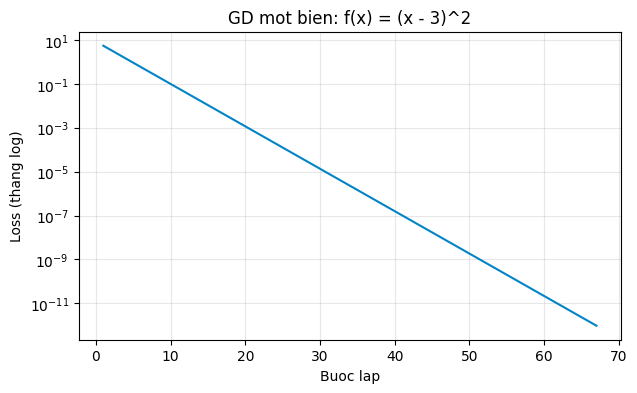

In [2]:
position, losses_one = gradient_descent_one_variable(
    learning_rate=FROM_SCRATCH_LEARNING_RATE,
    start=0.0,
    steps=FROM_SCRATCH_STEPS,
    tolerance=1e-12,
)

print(f"So buoc: {len(losses_one)}")
print(f"x cuoi : {position:.9f}")
print(f"x*     : 3.000000000")
print(f"loss   : {losses_one[-1]:.3e}")

plt.plot(range(1, len(losses_one) + 1), losses_one, color="#0284c7")
plt.yscale("log")
plt.xlabel("Buoc lap")
plt.ylabel("Loss (thang log)")
plt.title("GD mot bien: f(x) = (x - 3)^2")
plt.show()


## 2. Gradient Descent nhiều biến (hồi quy tuyến tính)

Hàm mất mát trung bình bình phương và gradient:

$$J(w) = \frac{1}{n}\lVert Xw - y \rVert^2, \qquad \nabla J(w) = \frac{2}{n} X^\top (Xw - y)$$

Dữ liệu sinh có chủ đích **lệch thang đo**: đặc trưng thứ hai có phương sai rất nhỏ,
nên gradient theo hướng đó nhỏ và GD thường hội tụ chậm theo hướng ấy.
Neo: Ch1 tr. 20–30.


Trong so GD            : [ 1.4941  2.0083 -0.2966]
Nghiem binh phuong toi thieu: [ 1.4965  1.9974 -2.9692]
MSE cuoi: 0.020938


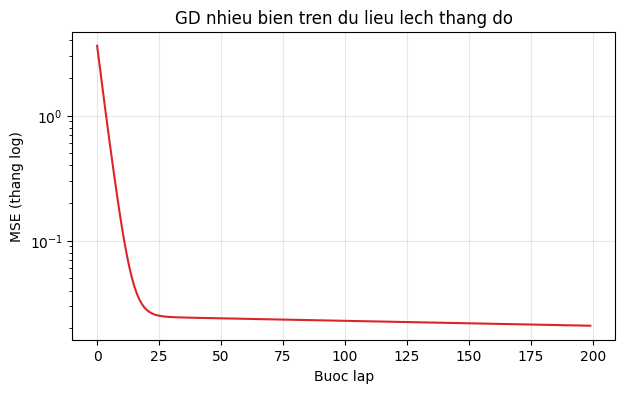

In [3]:
features, target = make_regression_data(FROM_SCRATCH_SAMPLE_COUNT, FROM_SCRATCH_SEED)
design = add_bias_column(features)

weights, losses_multi = gradient_descent(
    design, target, FROM_SCRATCH_LEARNING_RATE, FROM_SCRATCH_STEPS, tolerance=1e-14
)
reference, _, _, _ = np.linalg.lstsq(design, target, rcond=None)

print("Trong so GD            :", np.round(weights, 4))
print("Nghiem binh phuong toi thieu:", np.round(reference, 4))
print(f"MSE cuoi: {losses_multi[-1]:.6f}")

plt.plot(losses_multi, color="#dc2626")
plt.yscale("log")
plt.xlabel("Buoc lap")
plt.ylabel("MSE (thang log)")
plt.title("GD nhieu bien tren du lieu lech thang do")
plt.show()


## 3. Momentum và SGD / mini-batch

**Momentum** tích luỹ vận tốc, giúp đi nhanh theo hướng ổn định và giảm dao động
(Ch1 tr. 33–37):

$$v_{t+1} = m v_t - \eta \nabla J(w_t), \qquad w_{t+1} = w_t + v_{t+1}$$

**SGD / mini-batch** chỉ dùng một phần mẫu mỗi bước, giảm chi phí tính toán mỗi bước
(Ch1 tr. 39–43).


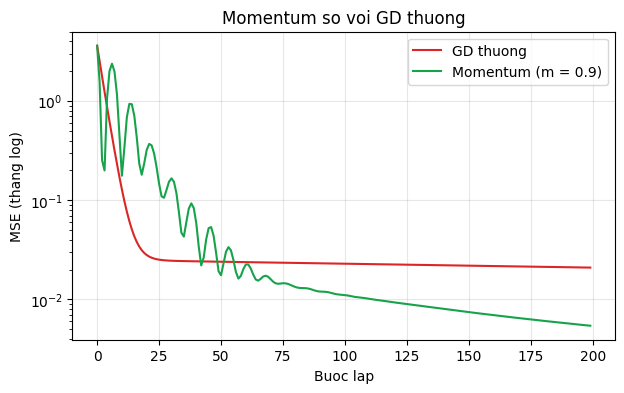

Loss GD thuong : 0.020938
Loss momentum  : 0.005429


In [4]:
weights_momentum, losses_momentum = gradient_descent_momentum(
    design, target, FROM_SCRATCH_LEARNING_RATE, momentum=0.9, steps=FROM_SCRATCH_STEPS
)

plt.plot(losses_multi, label="GD thuong", color="#dc2626")
plt.plot(losses_momentum, label="Momentum (m = 0.9)", color="#16a34a")
plt.yscale("log")
plt.xlabel("Buoc lap")
plt.ylabel("MSE (thang log)")
plt.title("Momentum so voi GD thuong")
plt.legend()
plt.show()

print(f"Loss GD thuong : {losses_multi[-1]:.6f}")
print(f"Loss momentum  : {losses_momentum[-1]:.6f}")


batch 1      loss cuoi = 0.002842
batch 16     loss cuoi = 0.004116
full-batch   loss cuoi = 0.020938


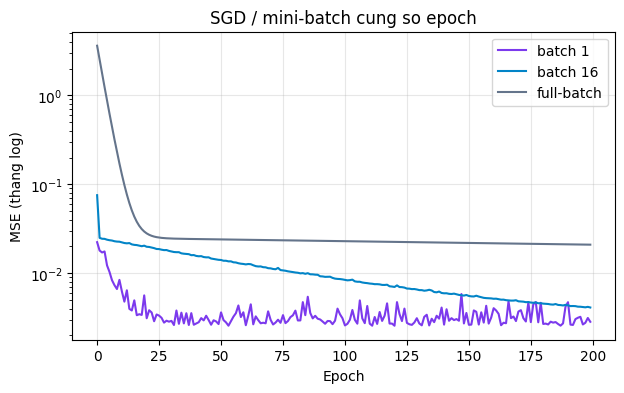

In [5]:
batch_sizes = [1, 16, FROM_SCRATCH_SAMPLE_COUNT]
colors = ["#7c3aed", "#0284c7", "#64748b"]

for batch_size, color in zip(batch_sizes, colors):
    _, losses_sgd = stochastic_gradient_descent(
        design, target, FROM_SCRATCH_LEARNING_RATE, batch_size,
        FROM_SCRATCH_STEPS, FROM_SCRATCH_SEED
    )
    label = "full-batch" if batch_size == FROM_SCRATCH_SAMPLE_COUNT else f"batch {batch_size}"
    plt.plot(losses_sgd, label=label, color=color)
    print(f"{label:<12} loss cuoi = {losses_sgd[-1]:.6f}")

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("MSE (thang log)")
plt.title("SGD / mini-batch cung so epoch")
plt.legend()
plt.show()


## 4. Sigmoid, Binary Cross-Entropy và kiểm tra gradient

$$a = \sigma(z) = \frac{1}{1 + e^{-z}}, \qquad
J(w) = -\frac{1}{n}\sum \left[ y \log a + (1-y)\log(1-a) \right]$$

Với sigmoid + BCE, đạo hàm theo trọng số rút gọn thành:

$$\nabla J(w) = \frac{1}{n} X^\top (a - y)$$

Neo: Ch3 phần 2 tr. 10–11.

**Kiểm tra gradient** so gradient giải tích với sai phân trung tâm:

$$\frac{\partial J}{\partial w_i} \approx \frac{J(w_i + \varepsilon) - J(w_i - \varepsilon)}{2\varepsilon}$$

Neo: Ch1 tr. 30; Ch3 phần 2 tr. 23.


In [6]:
class_features, class_target = make_classification_data(
    FROM_SCRATCH_SAMPLE_COUNT, FROM_SCRATCH_SEED
)
class_design = add_bias_column(class_features)

check_weights = np.array([0.2, -0.4, 0.3])
error = gradient_check(
    logistic_gradient, check_weights, class_design, class_target, GRADIENT_CHECK_EPSILON
)
print(f"Sai so tuong doi lon nhat: {error:.3e}")
print(f"Nguong chap nhan         : {GRADIENT_CHECK_TOLERANCE:.0e}")
print("KET LUAN:", "DAT" if error < GRADIENT_CHECK_TOLERANCE else "SAI")


Sai so tuong doi lon nhat: 1.419e-11
Nguong chap nhan         : 1e-06
KET LUAN: DAT


Trong so hoc duoc: [0.0031 1.4018 1.4076]
Loss cuoi        : 0.005668
Do chinh xac     : 1.0000


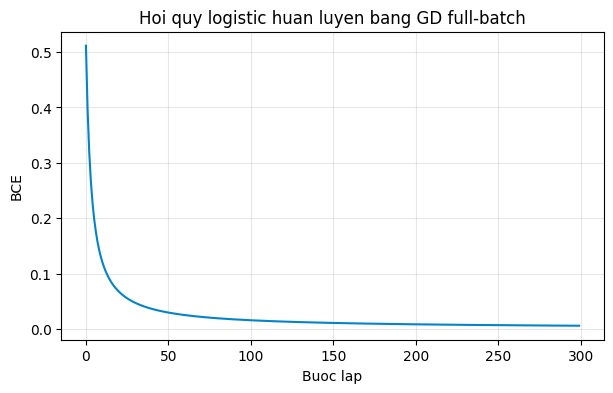

In [7]:
logistic_weights, logistic_losses = logistic_regression_fit(
    class_design, class_target, FROM_SCRATCH_LEARNING_RATE, 300
)
logistic_score = accuracy(logistic_weights, class_design, class_target)

print("Trong so hoc duoc:", np.round(logistic_weights, 4))
print(f"Loss cuoi        : {logistic_losses[-1]:.6f}")
print(f"Do chinh xac     : {logistic_score:.4f}")

plt.plot(logistic_losses, color="#0284c7")
plt.xlabel("Buoc lap")
plt.ylabel("BCE")
plt.title("Hoi quy logistic huan luyen bang GD full-batch")
plt.show()


## 5. Perceptron / PLA (CLO2)

Quy tắc cập nhật khi phân loại sai, với nhãn $y \in \{+1, -1\}$:

$$w \leftarrow w + \eta \, y \, x$$

Neo: Ch2 phần 2 tr. 5–29. PLA chỉ đảm bảo hội tụ khi dữ liệu **tách được tuyến tính**;
dữ liệu thật thường chồng lấn nên phải dùng pocket hoặc chấp nhận còn lỗi.


So vong      : 2
Loi vong cuoi: 0
Do chinh xac : 1.0000


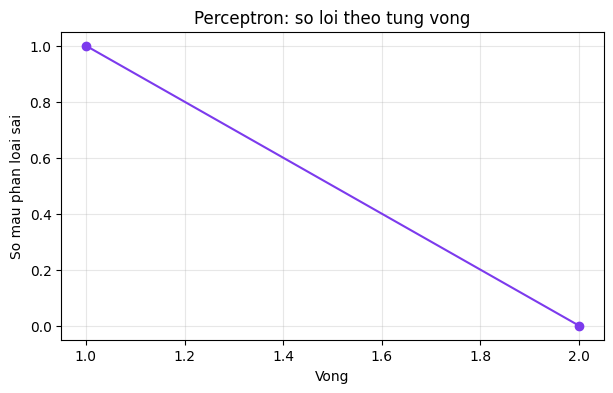

In [8]:
perceptron_weights, mistake_counts = perceptron_fit(
    class_features, class_target, learning_rate=1.0,
    steps=FROM_SCRATCH_STEPS, seed=FROM_SCRATCH_SEED
)
perceptron_score = perceptron_accuracy(perceptron_weights, class_features, class_target)

print(f"So vong      : {len(mistake_counts)}")
print(f"Loi vong cuoi: {mistake_counts[-1]}")
print(f"Do chinh xac : {perceptron_score:.4f}")

plt.plot(range(1, len(mistake_counts) + 1), mistake_counts, marker="o", color="#7c3aed")
plt.xlabel("Vong")
plt.ylabel("So mau phan loai sai")
plt.title("Perceptron: so loi theo tung vong")
plt.show()


## 6. MLP một tầng ẩn + lan truyền ngược (CLO3)

Lan truyền thuận:

$$z_1 = XW_1^\top + b_1, \quad a_1 = \sigma(z_1), \quad
z_2 = a_1W_2^\top + b_2, \quad a_2 = \sigma(z_2)$$

Lan truyền ngược với sigmoid + BCE:

$$\delta_2 = a_2 - y, \qquad \delta_1 = (\delta_2 W_2) \odot a_1 \odot (1 - a_1)$$

Neo: Ch3 phần 1 tr. 26–55; Ch3 phần 2 tr. 6–41.

**Vì sao dùng XOR:** không siêu phẳng nào tách được XOR, nên mô hình tuyến tính
(Logistic Regression, Perceptron) phải thất bại; MLP một tầng ẩn phải học được.
Đây là minh chứng cho vai trò của tầng ẩn.


In [9]:
xor_features, xor_target = make_xor_data()
check_parameters = make_mlp_parameters(input_size=2, hidden_size=3, seed=FROM_SCRATCH_SEED)

mlp_error = mlp_gradient_check(
    check_parameters, xor_features, xor_target, GRADIENT_CHECK_EPSILON
)
print(f"Sai so tuong doi lon nhat: {mlp_error:.3e}")
print(f"Nguong chap nhan         : {GRADIENT_CHECK_TOLERANCE:.0e}")
print("KET LUAN:", "DAT" if mlp_error < GRADIENT_CHECK_TOLERANCE else "SAI")


Sai so tuong doi lon nhat: 6.178e-08
Nguong chap nhan         : 1e-06
KET LUAN: DAT


Loss cuoi    : 0.000690
Do chinh xac : 1.0000


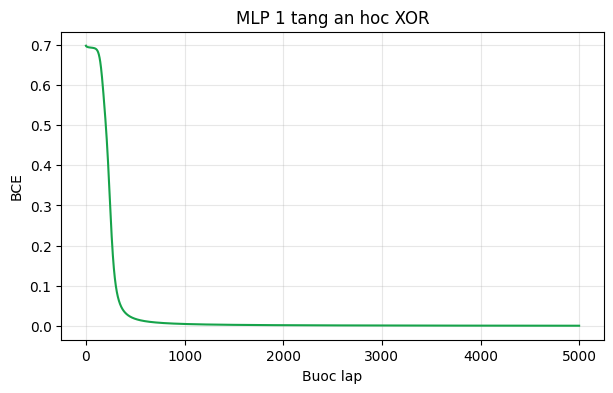

Du doan tung mau (nguong 0.5):
  x = [0. 0.], y = 0, p = 0.0008, du doan = 0
  x = [0. 1.], y = 1, p = 0.9993, du doan = 1
  x = [1. 0.], y = 1, p = 0.9993, du doan = 1
  x = [1. 1.], y = 0, p = 0.0006, du doan = 0


In [10]:
xor_parameters, xor_losses = mlp_fit(
    xor_features, xor_target, hidden_size=4, learning_rate=2.0,
    steps=5000, seed=FROM_SCRATCH_SEED
)
xor_score = mlp_accuracy(xor_parameters, xor_features, xor_target)

print(f"Loss cuoi    : {xor_losses[-1]:.6f}")
print(f"Do chinh xac : {xor_score:.4f}")

plt.plot(xor_losses, color="#16a34a")
plt.xlabel("Buoc lap")
plt.ylabel("BCE")
plt.title("MLP 1 tang an hoc XOR")
plt.show()

print("Du doan tung mau (nguong 0.5):")
for row, expected in zip(xor_features, xor_target):
    # Tinh lai xac suat cho tung dong de in bang.
    probability = float(mlp_forward(xor_parameters, row.reshape(1, -1))[0][0][0])
    print(f"  x = {row}, y = {int(expected[0])}, p = {probability:.4f}, "
          f"du doan = {int(probability >= 0.5)}")


## 7. Kết luận và giới hạn

**Kết quả minh hoạ**

- GD một biến hội tụ về đúng nghiệm giải tích $x^* = 3$.
- Momentum giảm MSE nhanh hơn GD thường trên dữ liệu lệch thang đo.
- Gradient check của Logistic Regression và MLP đều dưới ngưỡng $10^{-6}$,
  nghĩa là công thức lan truyền ngược được cài đúng.
- Perceptron học được dữ liệu gần tách được tuyến tính; MLP học được XOR.

**Giới hạn**

1. Các ví dụ chạy trên dữ liệu tổng hợp nhỏ, **không** chạy trên TF-IDF 50.000 chiều
   của đồ án. Vòng lặp Python thuần trên dữ liệu thật sẽ rất chậm, nên notebook này
   không thể tái tạo con số F1 0.9178 của mô hình chính.
2. Toàn bộ mã dùng để **chứng minh hiểu công thức**, không tối ưu tốc độ và không
   xử lý các vấn đề thực tế như dữ liệu mất cân bằng, nhiễu nhãn, hay regularization.
3. Perceptron không có cơ chế pocket; nếu dữ liệu chồng lấn, số lỗi có thể dao động
   và không bao giờ về 0. MLP có thể rơi vào cực trị địa phương tuỳ seed.
